# DIP Assignment 2 — Question 2

## Frequency-Domain Filtering

This executable notebook covers Sections 2.1, 2.2, and 2.3 of the official assignment. It locates the four supplied TIFF images programmatically, constructs ideal/Butterworth/Gaussian filters from their formulas, performs the required frequency-domain experiments, saves figures and CSV tables, and reports measured verification results.


## Scope, constraints, and conventions

The supplied images are loaded from `A2/Q2_images/`; no replacement or fabricated dataset is used. NumPy FFTs are permitted by the assignment. Transfer functions, radial grids, PSNR, power-retention calculations, ringing measurements, thresholding, and high-frequency emphasis are implemented explicitly. `scipy.ndimage.gaussian_filter` appears only in the expressly permitted Gaussian-equivalence check.

For an input of shape `(Ny, Nx)`, the default pipeline pads to `(2*Ny, 2*Nx)`, centers the spectrum with `fftshift`, multiplies by a centered transfer function, applies the inverse FFT, and crops the top-left `(Ny, Nx)` region. For the square step edge, this is exactly `P=1024` as required.


Python: 3.13.14 NumPy: 2.2.6 SciPy: 1.17.1 OS: Windows-11-10.0.26300-SP0 CPU: 13th Gen Intel(R) Core(TM) i7-13700HX total RAM bytes: 16886128640


OS: Windows-11-10.0.26300-SP0 CPU: 13th Gen Intel(R) Core(TM) i7-13700HX
{'file': 'cameraman.tif', 'path': 'D:\\College\\IIITH\\DIP\\Assignment-2\\DIP_A2\\A2\\Q2_images\\cameraman.tif', 'shape': '(512, 512)', 'dtype': 'uint8', 'min': 0, 'max': 255, 'dynamic range': 255}
{'file': 'Fig0441(a)(characters_test_pattern).tif', 'path': 'D:\\College\\IIITH\\DIP\\Assignment-2\\DIP_A2\\A2\\Q2_images\\Fig0441(a)(characters_test_pattern).tif', 'shape': '(688, 688)', 'dtype': 'uint8', 'min': 0, 'max': 255, 'dynamic range': 255}
{'file': 'Fig0419(a)(text_gaps_of_1_and_2_pixels).tif', 'path': 'D:\\College\\IIITH\\DIP\\Assignment-2\\DIP_A2\\A2\\Q2_images\\Fig0419(a)(text_gaps_of_1_and_2_pixels).tif', 'shape': '(444, 508)', 'dtype': 'uint8', 'min': 0, 'max': 255, 'dynamic range': 255}
{'file': 'Fig0457(a)(thumb_print).tif', 'path': 'D:\\College\\IIITH\\DIP\\Assignment-2\\DIP_A2\\A2\\Q2_images\\Fig0457(a)(thumb_print).tif', 'shape': '(962, 1026)', 'dtype': 'uint8', 'min': 52, 'max': 255, 'dynamic range'

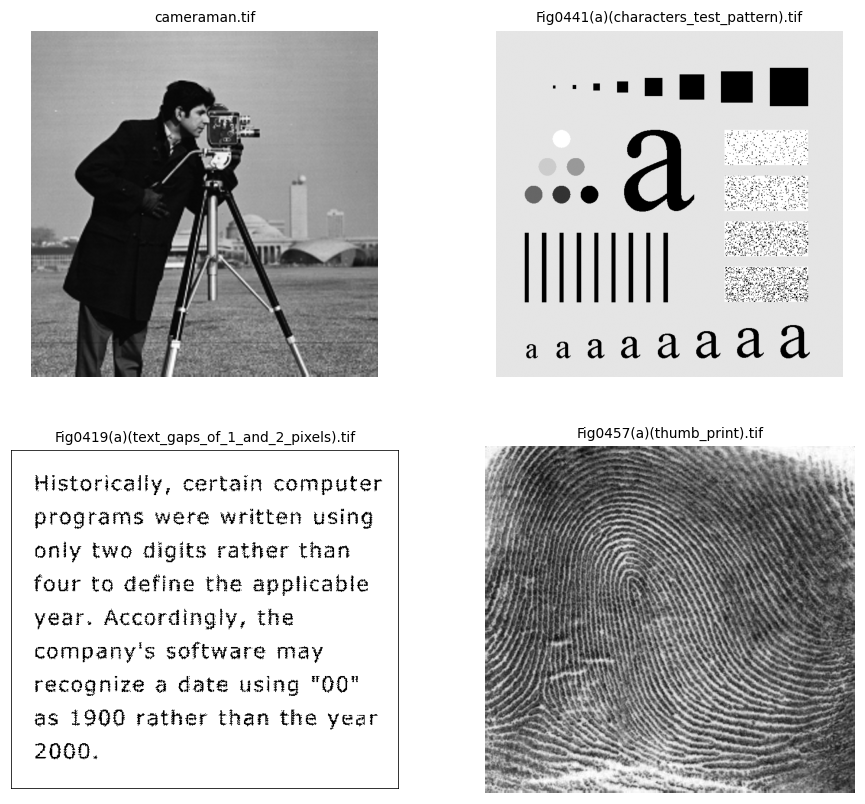

In [1]:
import csv
import os
import platform
import subprocess
import psutil
import scipy
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

def _exact_cpu_model():
    try:
        return subprocess.check_output(["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor | Select-Object -First 1 -ExpandProperty Name)"], text=True, stderr=subprocess.DEVNULL).strip() or platform.processor() or "not reported"
    except Exception:
        return platform.processor() or "not reported"

np.set_printoptions(precision=6, suppress=True)
plt.rcParams["figure.dpi"] = 110
ROOT = Path.cwd()
DATA = ROOT / "A2" / "Q2_images"
if not DATA.exists():
    found = list(ROOT.rglob("Q2_images"))
    if not found:
        raise FileNotFoundError("Could not locate A2/Q2_images.")
    DATA = found[0]
OUT = ROOT / "outputs" / "Q2"
FIG, TAB, FILT, VER, META = [OUT / x for x in ["figures", "tables", "filtered_images", "verification", "metadata"]]
for p in [FIG, TAB, FILT, VER, META]: p.mkdir(parents=True, exist_ok=True)

def savefig(name):
    path = FIG / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    return path

def write_rows(name, fields, rows):
    with open(TAB / name, "w", newline="", encoding="utf-8") as fh:
        w = csv.DictWriter(fh, fieldnames=fields); w.writeheader(); w.writerows(rows)

def load_gray(filename):
    candidates = list(DATA.rglob(filename))
    if not candidates:
        raise FileNotFoundError(f"Required image not found: {filename}")
    path = candidates[0]
    return np.asarray(Image.open(path)), path

names = [
    "cameraman.tif",
    "Fig0441(a)(characters_test_pattern).tif",
    "Fig0419(a)(text_gaps_of_1_and_2_pixels).tif",
    "Fig0457(a)(thumb_print).tif",
]
images = {}
inspection = []
fig, ax = plt.subplots(2, 2, figsize=(10, 9))
for a, name in zip(ax.ravel(), names):
    arr, path = load_gray(name)
    if arr.ndim != 2:
        raise ValueError(f"{name} is not grayscale: shape {arr.shape}")
    images[name] = arr
    inspection.append({"file": name, "path": str(path), "shape": str(arr.shape), "dtype": str(arr.dtype),
                       "min": int(arr.min()), "max": int(arr.max()), "dynamic range": int(arr.max()-arr.min())})
    a.imshow(arr, cmap="gray"); a.set_title(name, fontsize=9); a.axis("off")
print("Python:", sys.version.split()[0], "NumPy:", np.__version__, "SciPy:", scipy.__version__, "OS:", platform.platform(), "CPU:", _exact_cpu_model(), "total RAM bytes:", int(psutil.virtual_memory().total))
print("OS:", platform.platform(), "CPU:", _exact_cpu_model())
for row in inspection: print(row)
write_rows("00_dataset_inspection.csv", list(inspection[0]), inspection)
savefig("00_dataset_inspection.png"); plt.show()


## Frequency-domain pipeline and custom filter constructor

The centered frequency grid uses
\[
D(v,u)=\sqrt{(v-N_y/2)^2+(u-N_x/2)^2}.
\]
At `D=D0`, an ideal filter uses the stated `D <= D0` convention, Butterworth equals `1/2`, and Gaussian equals `exp(-1/2)`. Matching Gaussian half-amplitude to a Butterworth radius gives
\[
e^{-D_0^2/(2(D'_0)^2)}=1/2
\Rightarrow D'_0=D_0/\sqrt{2\ln 2}.
\]


In [2]:
def radial_grid(shape):
    ny, nx = shape
    v = np.arange(ny)[:, None] - ny/2
    u = np.arange(nx)[None, :] - nx/2
    return np.sqrt(v*v + u*u)

def make_filter(kind, P, D0, n=None, highpass=False):
    shape = (P, P) if np.isscalar(P) else tuple(P)
    if D0 <= 0 or not np.isfinite(D0): raise ValueError("D0 must be positive and finite.")
    if len(shape) != 2 or min(shape) <= 0: raise ValueError("shape must be two positive dimensions.")
    D = radial_grid(shape)
    kind = kind.lower()
    if kind == "ideal":
        H = (D <= D0).astype(float)
    elif kind == "butterworth":
        if n is None or int(n) != n or n < 1: raise ValueError("Butterworth order n must be a positive integer.")
        H = 1.0 / (1.0 + (D / D0)**(2*int(n)))
    elif kind == "gaussian":
        H = np.exp(-(D*D)/(2*D0*D0))
    else:
        raise ValueError("kind must be ideal, butterworth, or gaussian.")
    return 1.0 - H if highpass else H

def frequency_filter(image, H, crop=True):
    image = np.asarray(image, dtype=float)
    if image.ndim != 2 or H.shape != (2*image.shape[0], 2*image.shape[1]):
        raise ValueError(f"Expected H shape {(2*image.shape[0], 2*image.shape[1])}, got {H.shape}.")
    padded = np.zeros(H.shape, dtype=float); padded[:image.shape[0], :image.shape[1]] = image
    centered = np.fft.fftshift(np.fft.fft2(padded))
    filtered = np.fft.ifft2(np.fft.ifftshift(centered * H)).real
    return filtered[:image.shape[0], :image.shape[1]] if crop else filtered

def apply_filter(image, kind, D0, n=None, highpass=False, crop=True):
    return frequency_filter(image, make_filter(kind, (2*image.shape[0], 2*image.shape[1]), D0, n, highpass), crop)

def radial_profile(H):
    D = radial_grid(H.shape)
    r = np.rint(D).astype(int)
    sums = np.bincount(r.ravel(), weights=H.ravel())
    counts = np.bincount(r.ravel())
    return np.arange(len(sums)), sums / np.maximum(counts, 1)

def psnr(reference, estimate, peak=255.0):
    mse = np.mean((np.asarray(reference, float)-np.asarray(estimate, float))**2)
    return float("inf") if mse == 0 else float(10*np.log10(peak*peak/mse))

def finite_metrics(a, b):
    e = np.asarray(a)-np.asarray(b)
    return {"maximum absolute error": float(np.max(np.abs(e))),
            "mean absolute error": float(np.mean(np.abs(e))),
            "relative L2 error": float(np.linalg.norm(e)/max(np.linalg.norm(b), 1e-15))}


## Section 2.1(a) — Cutoff semantics and Gaussian matching

An ideal filter jumps from 1 to 0 at the cutoff and is exactly 1 under the `D <= D0` convention. A Butterworth filter has half-amplitude at `D0`; a Gaussian has `exp(-1/2) ≈ 0.6065` at its parameter `D0`. Therefore later Butterworth/Gaussian comparisons use `D0_gaussian = D0_butterworth / sqrt(2 ln 2)`.


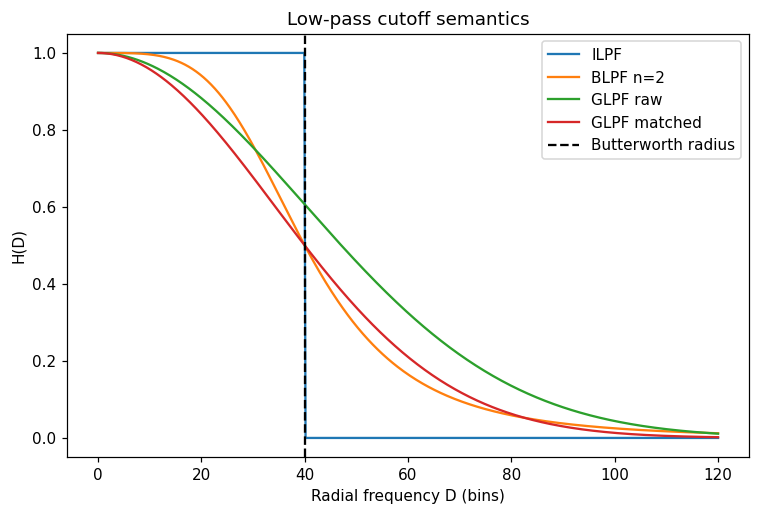

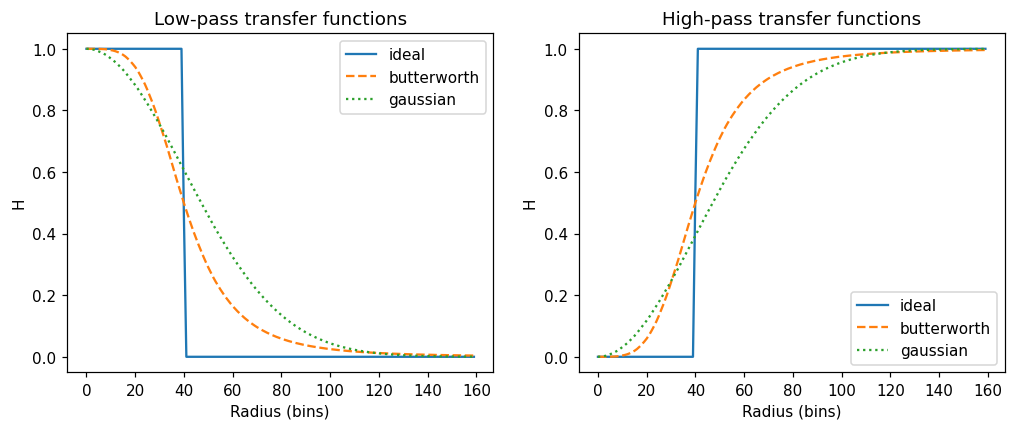

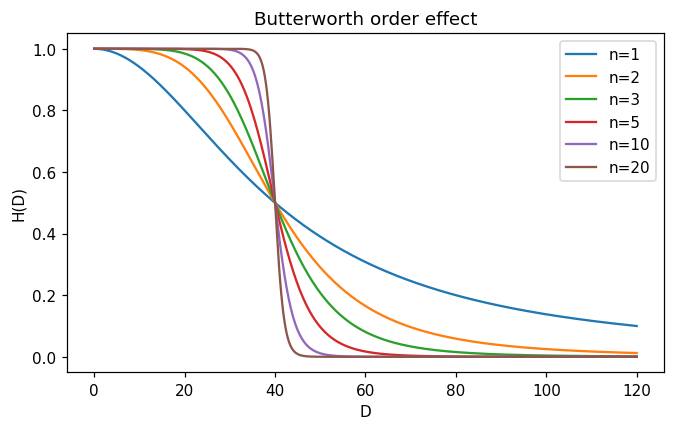

Matched Gaussian parameter: 33.972872011520764 cutoff checks: [{'check': 'BLPF(D0)=0.5', 'measured': 0.5, 'expected': 0.5, 'absolute error': 0.0, 'pass': True}, {'check': 'GLPF(D0)=exp(-1/2)', 'measured': np.float64(0.6065306597126334), 'expected': np.float64(0.6065306597126334), 'absolute error': np.float64(0.0), 'pass': np.True_}, {'check': 'matched GLPF(D0)=0.5', 'measured': np.float64(0.5), 'expected': 0.5, 'absolute error': np.float64(0.0), 'pass': np.True_}]


In [3]:
D0_demo, order_demo = 40.0, 2
matched_gaussian = D0_demo / np.sqrt(2*np.log(2))
values = []
for kind, d0, n in [("ideal",D0_demo,None),("butterworth",D0_demo,order_demo),("gaussian",D0_demo,None),("gaussian",matched_gaussian,None)]:
    for radius in [0.0, D0_demo, 1.5*D0_demo]:
        theoretical = {"ideal": float(radius <= d0), "butterworth": float(1/(1+(radius/d0)**(2*order_demo))),
                       "gaussian": float(np.exp(-radius**2/(2*d0**2)))}[kind]
        values.append({"filter": kind, "parameter D0": d0, "radius": radius, "theoretical": theoretical,
                       "label": "matched Gaussian" if d0 != D0_demo and kind=="gaussian" else ""})
write_rows("01_cutoff_values.csv", list(values[0]), values)
radii = np.linspace(0, 3*D0_demo, 500)
responses = {
    "ILPF": (radii <= D0_demo).astype(float),
    "BLPF n=2": 1/(1+(radii/D0_demo)**4),
    "GLPF raw": np.exp(-radii**2/(2*D0_demo**2)),
    "GLPF matched": np.exp(-radii**2/(2*matched_gaussian**2)),
}
plt.figure(figsize=(8,5))
for label, response in responses.items(): plt.plot(radii, response, label=label)
plt.axvline(D0_demo, color="k", ls="--", label="Butterworth radius")
plt.xlabel("Radial frequency D (bins)"); plt.ylabel("H(D)"); plt.title("Low-pass cutoff semantics"); plt.legend(); savefig("01_cutoff_semantics.png"); plt.show()
fig, ax = plt.subplots(1,2,figsize=(11,4))
for a, hp, title in zip(ax, [False, True], ["Low-pass transfer functions", "High-pass transfer functions"]):
    for kind, style in [("ideal","-"),("butterworth","--"),("gaussian",":")]:
        H = make_filter(kind, (512,512), D0_demo, order_demo if kind=="butterworth" else None, hp)
        r, prof = radial_profile(H); a.plot(r[:160], prof[:160], style, label=kind)
    a.set_title(title); a.set_xlabel("Radius (bins)"); a.set_ylabel("H"); a.legend()
savefig("02_six_filter_profiles.png"); plt.show()
order_rows = []
for n in [1,2,3,5,10,20]:
    order_rows.append({"order": n, "H(D0)": 1/(1+(D0_demo/D0_demo)**(2*n)), "H(2D0)": 1/(1+2**(2*n))})
write_rows("02_butterworth_orders.csv", list(order_rows[0]), order_rows)
plt.figure(figsize=(7,4))
for n in [1,2,3,5,10,20]: plt.plot(radii, 1/(1+(radii/D0_demo)**(2*n)), label=f"n={n}")
plt.xlabel("D"); plt.ylabel("H(D)"); plt.title("Butterworth order effect"); plt.legend(); savefig("03_butterworth_orders.png"); plt.show()
cutoff_checks = [
    {"check":"BLPF(D0)=0.5", "measured":1/(1+(D0_demo/D0_demo)**4), "expected":0.5},
    {"check":"GLPF(D0)=exp(-1/2)", "measured":np.exp(-.5), "expected":np.exp(-.5)},
    {"check":"matched GLPF(D0)=0.5", "measured":np.exp(-D0_demo**2/(2*matched_gaussian**2)), "expected":0.5},
]
for row in cutoff_checks: row["absolute error"]=abs(row["measured"]-row["expected"]); row["pass"]=row["absolute error"]<=1e-12
write_rows("03_cutoff_verification.csv", list(cutoff_checks[0]), cutoff_checks)
print("Matched Gaussian parameter:", matched_gaussian, "cutoff checks:", cutoff_checks)


## Section 2.1(b) — Spectral power retention

Power retention is computed from the centered spectrum as
\[
100\frac{\sum_{D\le r}|F|^2}{\sum |F|^2}.
\]
The radius is the smallest measured grid radius meeting each requested target. Low frequencies often dominate total energy, but fine text strokes and boundaries can remain perceptually important despite contributing less total power.


[{'target percent': 90, 'selected radius': 15.297058540778355, 'actual retained percent': 90.0032594092347, 'meets target': True}, {'target percent': 95, 'selected radius': 45.5411901469428, 'actual retained percent': 95.00006493854708, 'meets target': True}, {'target percent': 99, 'selected radius': 409.04400741240545, 'actual retained percent': 99.00001431801678, 'meets target': True}, {'target percent': 99.5, 'selected radius': 558.7351787743456, 'actual retained percent': 99.50000034927204, 'meets target': True}]


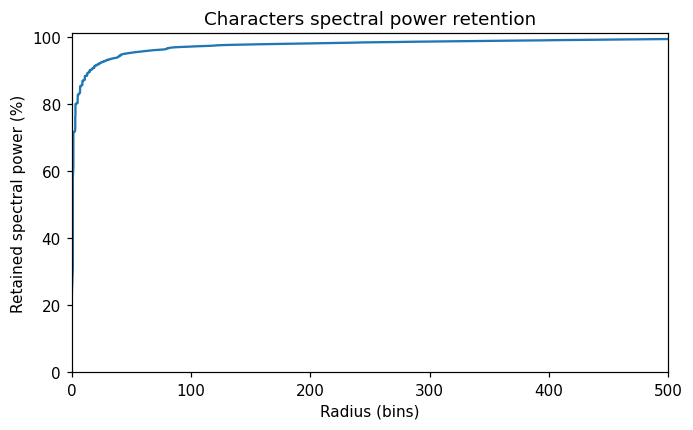

In [4]:
characters = images["Fig0441(a)(characters_test_pattern).tif"].astype(float)
char_pad = np.zeros((2*characters.shape[0],2*characters.shape[1]))
char_pad[:characters.shape[0],:characters.shape[1]] = characters
F_char = np.fft.fftshift(np.fft.fft2(char_pad))
D_char = radial_grid(F_char.shape)
power = np.abs(F_char)**2
order = np.argsort(D_char.ravel())
sorted_r = D_char.ravel()[order]; sorted_p = power.ravel()[order]
cumulative = 100*np.cumsum(sorted_p)/np.sum(sorted_p)
targets = [90,95,99,99.5]
power_rows=[]
for target in targets:
    idx = np.searchsorted(cumulative, target)
    radius = float(sorted_r[idx]); actual = float(cumulative[idx])
    power_rows.append({"target percent":target,"selected radius":radius,"actual retained percent":actual,
                       "meets target":actual>=target})
write_rows("04_power_retention.csv", list(power_rows[0]), power_rows)
print(power_rows)
plt.figure(figsize=(7,4)); plt.plot(sorted_r, cumulative); plt.xlim(0, min(sorted_r.max(),500)); plt.ylim(0,101)
plt.xlabel("Radius (bins)"); plt.ylabel("Retained spectral power (%)"); plt.title("Characters spectral power retention")
savefig("04_power_retention.png"); plt.show()


## Section 2.1(c) — Inverse Butterworth design

From `H(10)=16/17`, `(10/D0)^(2n)=1/16`; from `H(40)=1/17`, `(40/D0)^(2n)=16`. Dividing gives `4^(2n)=256=4^4`, hence `n=2`; substituting gives `D0=20`. For the additional condition `H(2D0) <= .01`, solve `1/(1+2^(2n)) <= .01`, so `2^(2n) >= 99` and the smallest integer order is `n=4`.


In [5]:
design_rows=[]
n_recovered, d0_recovered = 2, 20.0
for label, measured, expected in [
    ("H(10)", 1/(1+(10/d0_recovered)**(2*n_recovered)), 16/17),
    ("H(40)", 1/(1+(40/d0_recovered)**(2*n_recovered)), 1/17),
    ("minimum n at 2D0", 1/(1+2**(2*4)), .01),
]:
    ok = measured <= expected if label == "minimum n at 2D0" else abs(measured-expected) <= 1e-12
    design_rows.append({"design problem":label,"analytical result":expected,"numerical result":measured,
                        "absolute error":abs(measured-expected),"pass":bool(ok)})
write_rows("05_inverse_butterworth.csv", list(design_rows[0]), design_rows)
print("Recovered n =",n_recovered,"D0 =",d0_recovered,"minimum order =",4, design_rows)


Recovered n = 2 D0 = 20.0 minimum order = 4 [{'design problem': 'H(10)', 'analytical result': 0.9411764705882353, 'numerical result': 0.9411764705882353, 'absolute error': 0.0, 'pass': True}, {'design problem': 'H(40)', 'analytical result': 0.058823529411764705, 'numerical result': 0.058823529411764705, 'absolute error': 0.0, 'pass': True}, {'design problem': 'minimum n at 2D0', 'analytical result': 0.01, 'numerical result': 0.0038910505836575876, 'absolute error': 0.006108949416342413, 'pass': True}]


## Section 2.2 — Ringing prediction and synthetic step edge

### Dated analytical prediction (2026-10-28)

Away from the square corners, the center row behaves approximately as a one-dimensional step. An ideal radial low-pass retains the `v=0` frequency line, so its continuous approximation for a unit step at edge coordinate `x=0` is
\[
g(x)=\frac12+\frac1\pi\operatorname{Si}\left(\frac{2\pi D_0x}{P}\right).
\]
For intensities `A=50`, `B=200`, the predicted profile is `A+(B-A)g(x)`. The first overshoot is the first positive maximum of this formula and its distance scales as `P/D0`; the ideal-filter overshoot is the Gibbs phenomenon. On the finite discrete grid, the measured maximum can differ because the radial mask is sampled, the square has an opposite edge, and the 2-D corner is not a 1-D step.

For a Gaussian low-pass, the continuous spatial kernel is non-negative and its step response is the Gaussian CDF:
\[
g_G(x)=\frac12[1+\operatorname{erf}(x/(\sqrt2\sigma_s))],
\quad \sigma_s=P/(2\pi D_0).
\]
It is monotonic and has no ideal overshoot. Discrete sampling, finite support, padding, and the square's second edge can create small implementation deviations.


Step square coordinates: 128 383 shape: (256, 256) values: [ 50. 200.]


C:\Users\Acer\AppData\Local\Temp\ipykernel_36692\2483656344.py:14: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  t=np.linspace(0,val,20001); out[i]=np.trapz(np.sinc(t/np.pi), t)


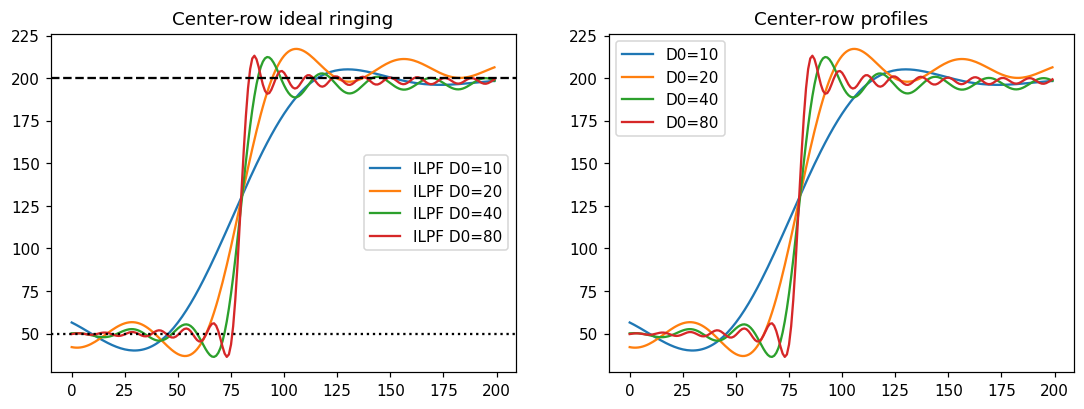

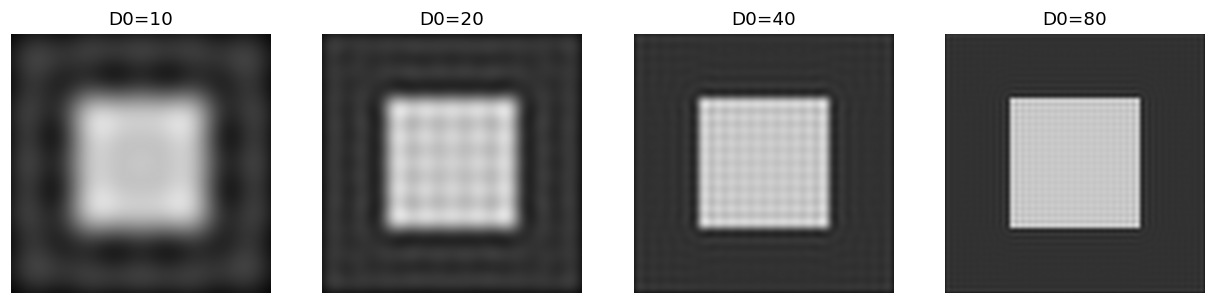

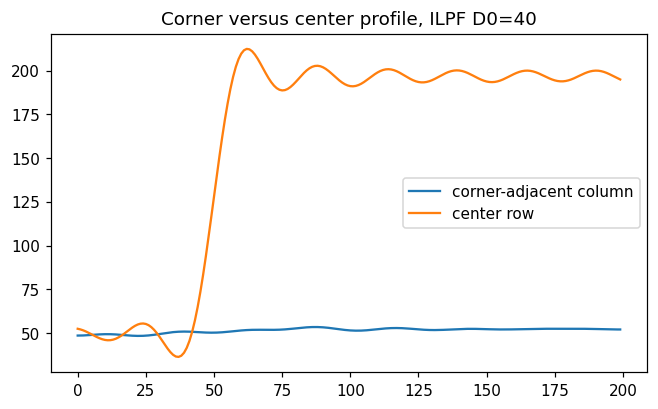

In [6]:
Nstep = 512; Pstep = 1024; A, B, side = 50.0, 200.0, 256
step = np.full((Nstep,Nstep), A)
lo, hi = (Nstep-side)//2, (Nstep+side)//2
step[lo:hi,lo:hi] = B
assert step.shape==(512,512) and np.all(step[:lo,:]==A) and np.all(step[lo:hi,lo:hi]==B)
Image.fromarray(step.astype(np.uint8)).save(FILT/"synthetic_step_edge.png")
print("Step square coordinates:", lo, hi-1, "shape:", step[lo:hi,lo:hi].shape, "values:", np.unique(step))

def si_numeric(z):
    # Sine integral by a dense trapezoidal integration for prediction only.
    z=np.asarray(z,float); out=np.zeros_like(z)
    for i, val in np.ndenumerate(z):
        if abs(val)<1e-12: out[i]=0; continue
        t=np.linspace(0,val,20001); out[i]=np.trapz(np.sinc(t/np.pi), t)
    return out

def profile_overshoot(profile):
    edge = lo
    right = profile[edge:edge+120]
    peak_index = int(np.argmax(right))
    return float((right[peak_index]-B)/(B-A)*100), peak_index

ideal_rows=[]
center_profile_rows={}
for d0 in [10,20,40,80]:
    filtered=apply_filter(step,"ideal",d0)
    profile=filtered[Nstep//2,:]
    center_profile_rows[f"ILPF D0={d0}"]=profile
    x=np.arange(-120,121)
    predicted=A+(B-A)*(.5+si_numeric(2*np.pi*d0*x/Pstep)/np.pi)
    pred_peak=int(np.argmax(predicted)); pred_os=float((predicted[pred_peak]-B)/(B-A)*100)
    measured_os, measured_dist=profile_overshoot(profile)
    ideal_rows.append({"D0":d0,"predicted overshoot percent":pred_os,"measured overshoot percent":measured_os,
                       "overshoot absolute discrepancy":abs(pred_os-measured_os),
                       "predicted peak distance":abs(int(x[pred_peak])),"measured peak distance":measured_dist,
                       "distance absolute discrepancy":abs(abs(int(x[pred_peak]))-measured_dist)})
write_rows("06_ideal_ringing.csv", list(ideal_rows[0]), ideal_rows)
fig, ax=plt.subplots(1,2,figsize=(12,4))
for label,p in center_profile_rows.items(): ax[0].plot(p[lo-80:lo+120],label=label)
ax[0].axhline(A,color="k",ls=":"); ax[0].axhline(B,color="k",ls="--"); ax[0].legend(); ax[0].set_title("Center-row ideal ringing")
for d0 in [10,20,40,80]: ax[1].plot(center_profile_rows[f"ILPF D0={d0}"][lo-80:lo+120],label=f"D0={d0}")
ax[1].set_title("Center-row profiles"); ax[1].legend()
savefig("05_ideal_ringing_profiles.png"); plt.show()
fig,ax=plt.subplots(1,4,figsize=(14,4))
for a,d0 in zip(ax,[10,20,40,80]): a.imshow(apply_filter(step,"ideal",d0),cmap="gray",vmin=0,vmax=255); a.set_title(f"D0={d0}"); a.axis("off")
savefig("06_ideal_ringing_images.png"); plt.show()
corner=apply_filter(step,"ideal",40)
plt.figure(figsize=(7,4)); plt.plot(corner[lo-50:lo+150,lo-50].ravel(),label="corner-adjacent column"); plt.plot(corner[Nstep//2,lo-50:lo+150],label="center row"); plt.legend(); plt.title("Corner versus center profile, ILPF D0=40"); savefig("07_corner_analysis.png"); plt.show()


## Section 2.2(b) — Butterworth order sweep and non-negative-kernel proof

For a normalized kernel `h[k] >= 0` with `sum(h)=1`, convolution is a weighted average. If every input sample lies in `[A,B]`, then `A*sum(h) <= sum(h[k]f[x-k]) <= B*sum(h)`, hence the output remains in `[A,B]` and cannot overshoot. Negative kernel lobes break this weighted-average argument and permit ringing.


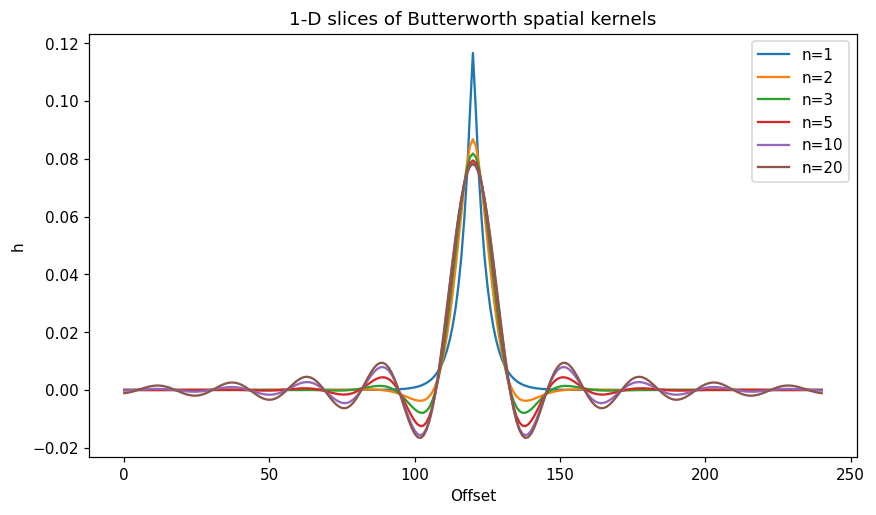

[{'order': 1, 'measured overshoot percent': 9.302373011147816e-06, 'kernel minimum': -2.9379320141368036e-07, 'kernel maximum': 0.11662731592919354, 'kernel ratio abs(min)/max': 2.5190771053330877e-06, 'peak distance': 71}, {'order': 2, 'measured overshoot percent': 3.359016669890328, 'kernel minimum': -0.0037487489945879854, 'kernel maximum': 0.08676263990246091, 'kernel ratio abs(min)/max': 0.04320694942895181, 'peak distance': 13}, {'order': 3, 'measured overshoot percent': 5.603169578899346, 'kernel minimum': -0.007906274945408999, 'kernel maximum': 0.08181226321207014, 'kernel ratio abs(min)/max': 0.09663924007229457, 'peak distance': 12}, {'order': 5, 'measured overshoot percent': 7.49947861957376, 'kernel minimum': -0.012529112710338016, 'kernel maximum': 0.07942505769148475, 'kernel ratio abs(min)/max': 0.15774760603896013, 'peak distance': 12}, {'order': 10, 'measured overshoot percent': 8.486465735608817, 'kernel minimum': -0.015685247980398984, 'kernel maximum': 0.0784472034

In [7]:
bw_rows=[]; kernel_profiles={}
for n in [1,2,3,5,10,20]:
    filtered=apply_filter(step,"butterworth",40,n)
    os_pct, dist=profile_overshoot(filtered[Nstep//2,:])
    H=make_filter("butterworth",Pstep,40,n=n)
    H1=H[Pstep//2,:]
    kernel=np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(H1))).real
    kernel_profiles[f"n={n}"]=kernel
    bw_rows.append({"order":n,"measured overshoot percent":os_pct,"kernel minimum":float(kernel.min()),
                    "kernel maximum":float(kernel.max()),"kernel ratio abs(min)/max":float(abs(kernel.min())/max(kernel.max(),1e-15)),
                    "peak distance":dist})
write_rows("07_butterworth_order_sweep.csv",list(bw_rows[0]),bw_rows)
plt.figure(figsize=(9,5))
for label,k in kernel_profiles.items(): plt.plot(k[Pstep//2-120:Pstep//2+121],label=label)
plt.title("1-D slices of Butterworth spatial kernels"); plt.xlabel("Offset"); plt.ylabel("h"); plt.legend(); savefig("08_butterworth_kernels.png"); plt.show()
print(bw_rows)


## Section 2.2(c) — Characters comparison

The four radii measured from spectral power retention are applied to ideal, second-order Butterworth, and matched-half-amplitude Gaussian filters. The ideal filter is expected to preserve sharper transitions but may introduce ringing; Gaussian attenuation is smoother, while Butterworth provides an intermediate transition controlled by order.


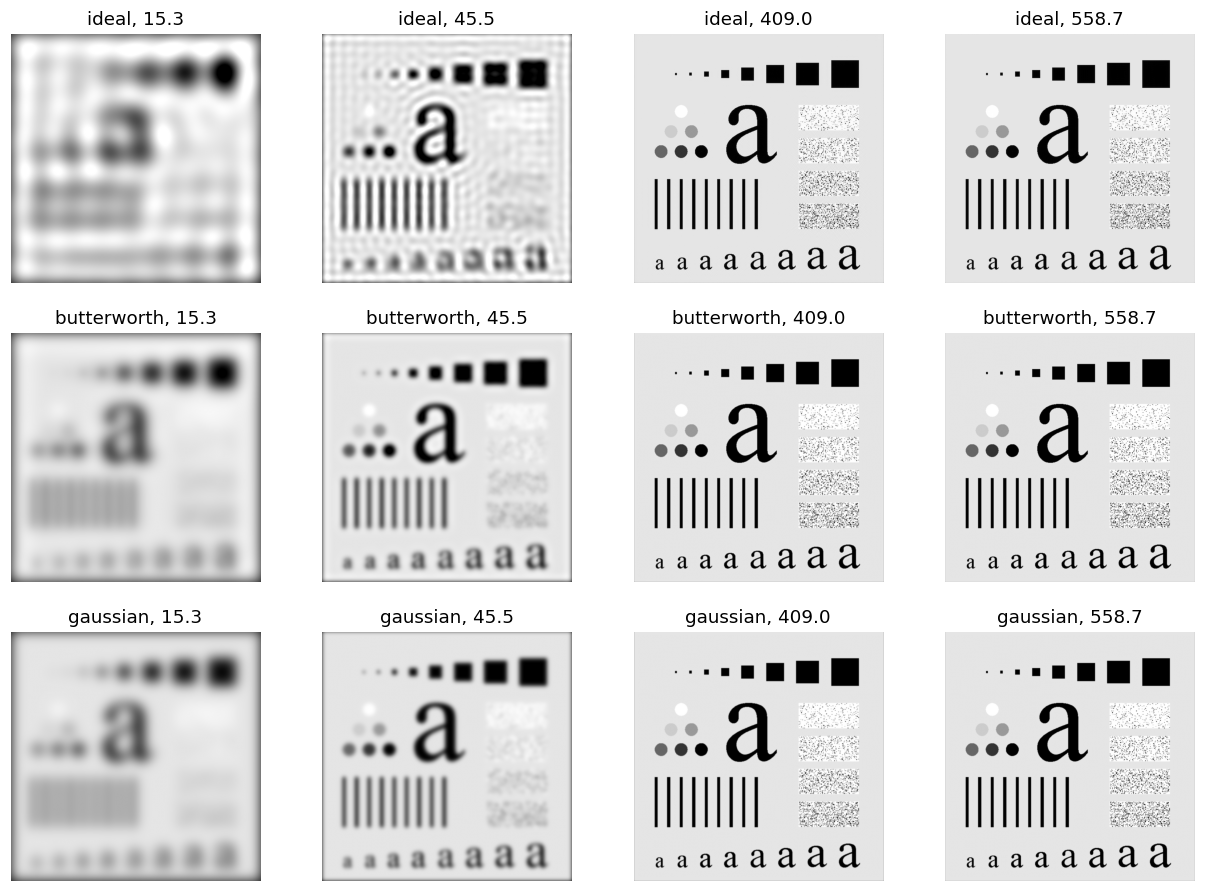

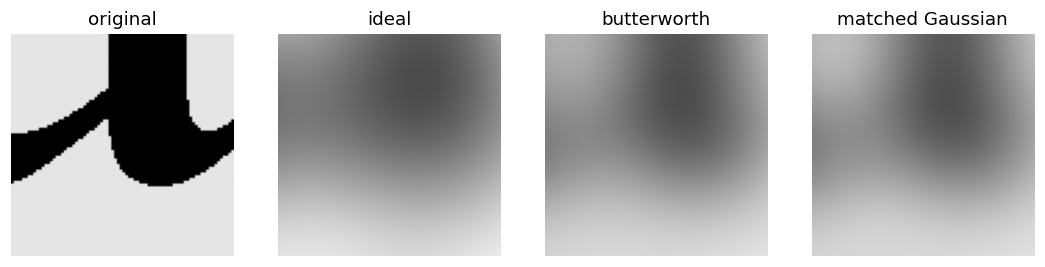

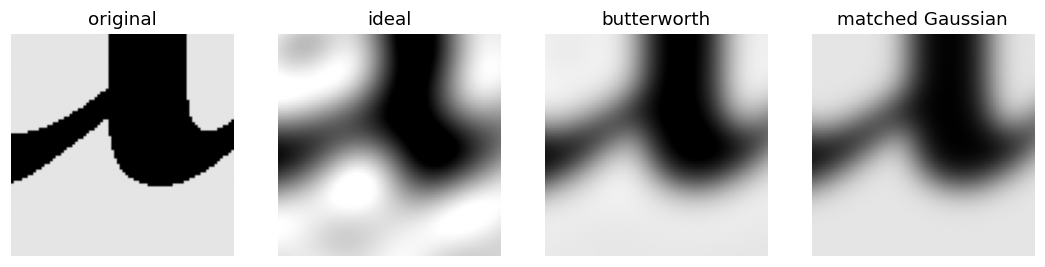

In [8]:
char_results={}
fig,ax=plt.subplots(3,4,figsize=(14,10))
for i,(kind,n) in enumerate([("ideal",None),("butterworth",2),("gaussian",None)]):
    for j,row in enumerate(power_rows):
        d0=row["selected radius"]
        actual_d0=d0/np.sqrt(2*np.log(2)) if kind=="gaussian" else d0
        result=apply_filter(characters,kind,actual_d0,n)
        char_results[(kind,j)]=result
        Image.fromarray(np.clip(result,0,255).astype(np.uint8)).save(FILT/f"characters_{kind}_{j}.png")
        ax[i,j].imshow(result,cmap="gray",vmin=0,vmax=255); ax[i,j].set_title(f"{kind}, {d0:.1f}"); ax[i,j].axis("off")
savefig("09_characters_filter_grid.png"); plt.show()
for j in [0,1]:
    fig,ax=plt.subplots(1,4,figsize=(12,3))
    y,x=characters.shape[0]//2, characters.shape[1]//2
    crop=(slice(y-40,y+40),slice(x-40,x+40))
    for a,z,title in zip(ax,[characters,char_results[("ideal",j)],char_results[("butterworth",j)],char_results[("gaussian",j)]],
                         ["original","ideal","butterworth","matched Gaussian"]):
        a.imshow(z[crop],cmap="gray",vmin=0,vmax=255); a.set_title(title); a.axis("off")
    savefig(f"10_character_zoom_{j}.png"); plt.show()


## Section 2.2(d) — Gaussian equivalence

For the DFT-bin frequency `D`, physical angular frequency is `omega = 2*pi*D/P`. The continuous Gaussian transform is `exp(-sigma_s^2 omega^2/2)`. Equating this with `exp(-D^2/(2D0^2))` gives `sigma_s^2*(2*pi/P)^2 = 1/D0^2`, therefore
\[
\sigma_s=P/(2\pi D_0).
\]
The permitted spatial reference uses `scipy.ndimage.gaussian_filter(mode='constant', cval=0, truncate=4)`. It is not expected to match exactly because it uses a truncated sampled kernel while the frequency-domain operation is periodic on a finite padded grid.


In [9]:
gauss_rows=[]
for d0 in [10,40,160]:
    sigma=Pstep/(2*np.pi*d0)
    custom=apply_filter(step,"gaussian",d0)
    reference=ndimage.gaussian_filter(step,sigma=sigma,mode="constant",cval=0,truncate=4)
    metrics=finite_metrics(custom,reference)
    gauss_rows.append({"D0":d0,"P":Pstep,"sigma_s":sigma,"boundary":"constant cval=0, truncate=4",**metrics})
write_rows("08_gaussian_equivalence.csv",list(gauss_rows[0]),gauss_rows)
print(gauss_rows)


[{'D0': 10, 'P': 1024, 'sigma_s': 16.297466172610083, 'boundary': 'constant cval=0, truncate=4', 'maximum absolute error': 0.008742199978200915, 'mean absolute error': 0.0022890839369182, 'relative L2 error': 2.8347794111792784e-05}, {'D0': 40, 'P': 1024, 'sigma_s': 4.074366543152521, 'boundary': 'constant cval=0, truncate=4', 'maximum absolute error': 0.007365758521387988, 'mean absolute error': 0.0005421967072977657, 'relative L2 error': 1.1469747069922419e-05}, {'D0': 160, 'P': 1024, 'sigma_s': 1.0185916357881302, 'boundary': 'constant cval=0, truncate=4', 'maximum absolute error': 0.06565123692092811, 'mean absolute error': 0.002222797368219277, 'relative L2 error': 5.894220428394721e-05}]


## Section 2.3(a) — Noise–blur trade-off

A single fixed Gaussian-noise realization with standard deviation 20 is used for every family and cutoff. PSNR is computed against the original floating-point cameraman image. Noisy values are not clipped for the experiment; clipping is used only for display. The official sweep is exactly `D0=5..150` inclusive for Ideal, second-order Butterworth, and Gaussian filters. If the largest PSNR occurs at `D0=150`, it is reported as the maximum within the tested range, not as a proven global optimum.


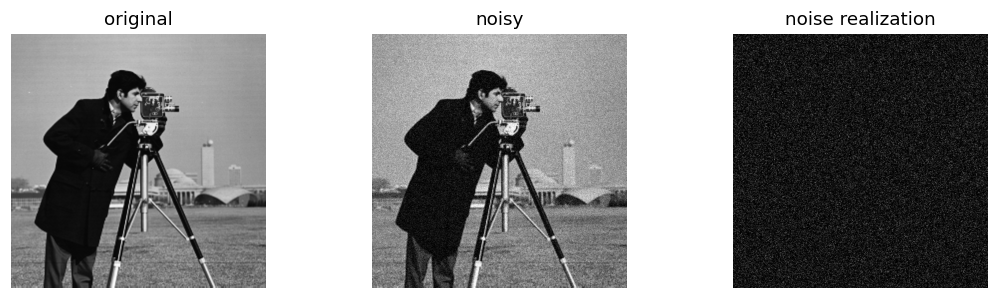

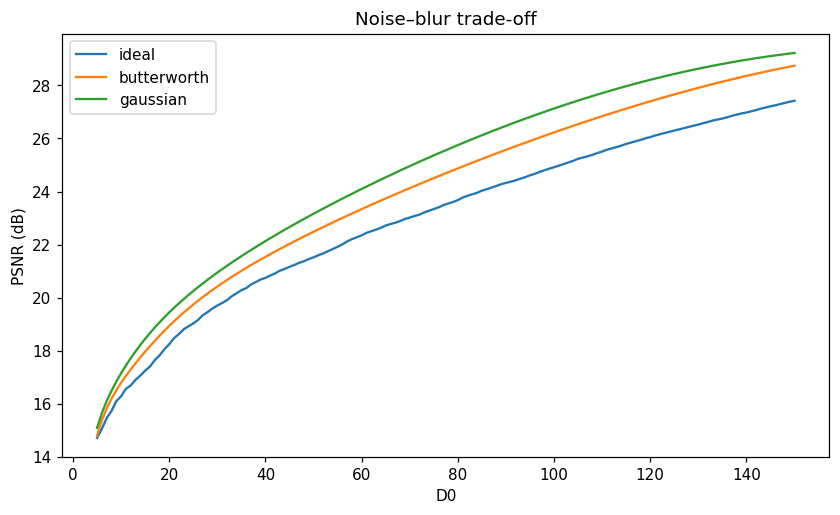

PSNR optima: [{'filter': 'ideal', 'order': '', 'D0': 150, 'PSNR': 27.418738356454075}, {'filter': 'butterworth', 'order': 2, 'D0': 150, 'PSNR': 28.739803391344978}, {'filter': 'gaussian', 'order': '', 'D0': 150, 'PSNR': 29.219380604766005}]


In [10]:
cameraman=images["cameraman.tif"].astype(float)
rng=np.random.default_rng(20261028)
noise=rng.normal(0,20,cameraman.shape)
noisy=cameraman+noise
plt.figure(figsize=(12,3))
for i,(z,title) in enumerate([(cameraman,"original"),(noisy,"noisy"),(noise,"noise realization")]):
    plt.subplot(1,3,i+1); plt.imshow(z,cmap="gray",vmin=0,vmax=255 if i<2 else None); plt.title(title); plt.axis("off")
savefig("11_noise_input.png"); plt.show()
psnr_rows=[]
for kind,n in [("ideal",None),("butterworth",2),("gaussian",None)]:
    for d0 in range(5,151):
        filtered=apply_filter(noisy,kind,d0,n)
        psnr_rows.append({"filter":kind,"order":n or "","D0":d0,"PSNR":psnr(cameraman,filtered)})
write_rows("09_psnr_sweep.csv",list(psnr_rows[0]),psnr_rows)
plt.figure(figsize=(9,5))
for kind in ["ideal","butterworth","gaussian"]:
    subset=[r for r in psnr_rows if r["filter"]==kind]
    plt.plot([r["D0"] for r in subset],[r["PSNR"] for r in subset],label=kind)
plt.xlabel("D0"); plt.ylabel("PSNR (dB)"); plt.title("Noise–blur trade-off"); plt.legend(); savefig("12_psnr_tradeoff.png"); plt.show()
best_rows=[]
for kind in ["ideal","butterworth","gaussian"]:
    subset=[r for r in psnr_rows if r["filter"]==kind]; best=max(subset,key=lambda r:r["PSNR"]); best_rows.append(best)
write_rows("10_psnr_optima.csv",list(best_rows[0]),best_rows); print("PSNR optima:",best_rows)


## Section 2.3(b) — Character repair

Candidate Gaussian cutoffs are evaluated on the supplied text-gap image. The selected parameter is recorded from the actual candidate set rather than assumed. The ideal comparison uses the same half-amplitude radius (`D0_ideal = sqrt(2 ln 2) * D0_gaussian`) and is interpreted with attention to ringing around thin strokes.


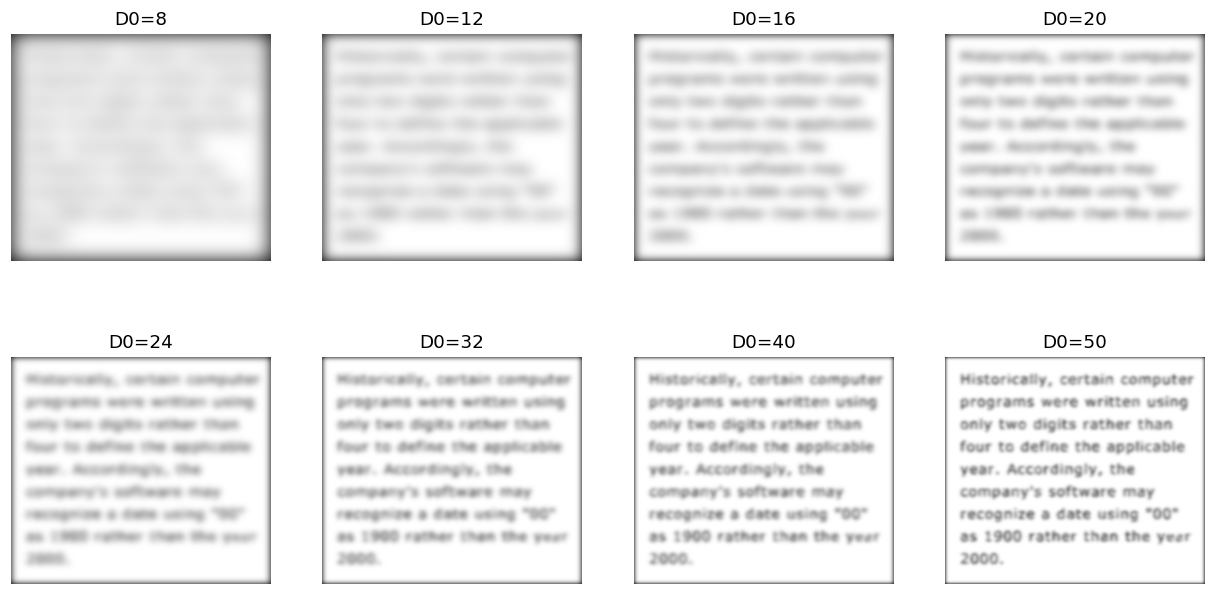

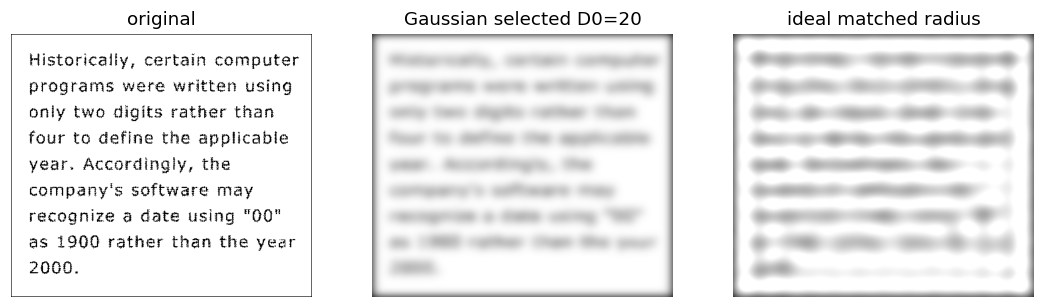

In [11]:
textgaps=images["Fig0419(a)(text_gaps_of_1_and_2_pixels).tif"].astype(float)
repair_rows=[]; repair_candidates=[8,12,16,20,24,32,40,50]
fig,ax=plt.subplots(2,4,figsize=(14,7))
for a,d0 in zip(ax.ravel(),repair_candidates):
    z=apply_filter(textgaps,"gaussian",d0); repair_candidates_result=z
    repair_rows.append({"gaussian D0":d0,"mean":float(z.mean()),"std":float(z.std()),"min":float(z.min()),"max":float(z.max())})
    a.imshow(z,cmap="gray",vmin=0,vmax=255); a.set_title(f"D0={d0}"); a.axis("off")
savefig("13_character_repair_candidates.png"); plt.show()
selected_repair=20
repaired=apply_filter(textgaps,"gaussian",selected_repair)
ideal_repair=apply_filter(textgaps,"ideal",selected_repair*np.sqrt(2*np.log(2)))
Image.fromarray(np.clip(repaired,0,255).astype(np.uint8)).save(FILT/"text_repaired_gaussian.png")
Image.fromarray(np.clip(ideal_repair,0,255).astype(np.uint8)).save(FILT/"text_repaired_ideal_comparison.png")
write_rows("11_character_repair.csv",list(repair_rows[0]),repair_rows)
fig,ax=plt.subplots(1,3,figsize=(12,4))
for a,z,title in zip(ax,[textgaps,repaired,ideal_repair],["original","Gaussian selected D0=20","ideal matched radius"]):
    a.imshow(z,cmap="gray",vmin=0,vmax=255); a.set_title(title); a.axis("off")
savefig("14_character_repair_comparison.png"); plt.show()


## Section 2.3(c) — High-pass filtering, DC, emphasis, and ridge map

The common nominal radius is `R=40`. The fourth-order Butterworth and matched Gaussian high-pass filters have half-amplitude at `R`; the ideal high-pass has a discontinuous nominal cutoff and no true half-amplitude point. All low-pass-derived high-pass filters have `H(center)=0`, so the full padded output has negligible mean, while the cropped mean can differ because cropping removes padded zero regions.


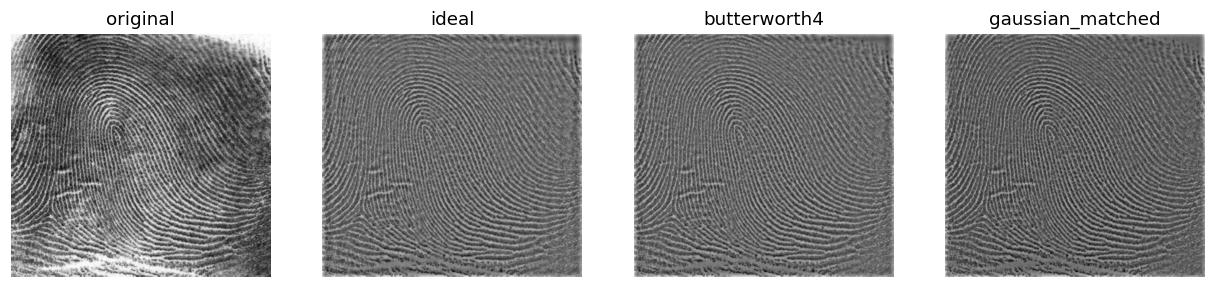

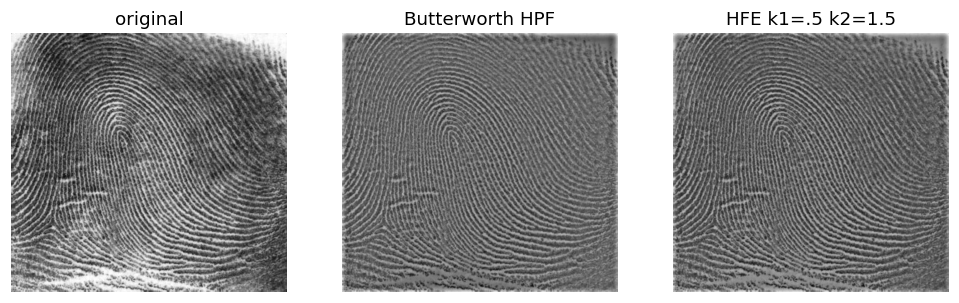

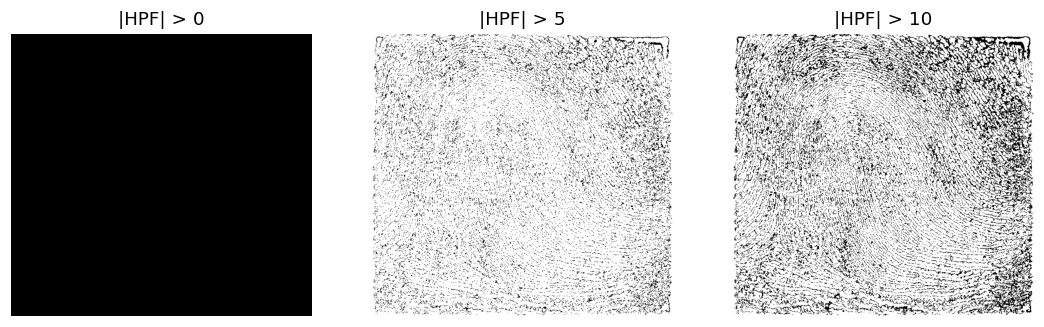

High-pass metrics: [{'filter': 'ideal', 'cropped mean': 1.7066307446854785, 'cropped std': 32.709066824027836, 'minimum': -123.95258130891476, 'maximum': 166.94282268495832}, {'filter': 'butterworth4', 'cropped mean': 1.7535428240590991, 'cropped std': 32.24969882084754, 'minimum': -119.13021141114857, 'maximum': 167.12137048538722}, {'filter': 'gaussian_matched', 'cropped mean': 2.4846282965096727, 'cropped std': 31.581812110184956, 'minimum': -101.84239953374583, 'maximum': 166.52782895641016}]


In [12]:
thumb=images["Fig0457(a)(thumb_print).tif"].astype(float)
R=40.0; gauss_hp_d0=R/np.sqrt(2*np.log(2))
hp_outputs={
    "ideal":apply_filter(thumb,"ideal",R,highpass=True),
    "butterworth4":apply_filter(thumb,"butterworth",R,n=4,highpass=True),
    "gaussian_matched":apply_filter(thumb,"gaussian",gauss_hp_d0,highpass=True),
}
hp_rows=[]
for label,z in hp_outputs.items():
    full=frequency_filter(thumb,make_filter("ideal",(2*thumb.shape[0],2*thumb.shape[1]),R,highpass=True),crop=False) if label=="ideal" else None
    hp_rows.append({"filter":label,"cropped mean":float(z.mean()),"cropped std":float(z.std()),"minimum":float(z.min()),"maximum":float(z.max())})
fig,ax=plt.subplots(1,4,figsize=(14,4))
ax[0].imshow(thumb,cmap="gray"); ax[0].set_title("original"); ax[0].axis("off")
for a,(label,z) in zip(ax[1:],hp_outputs.items()):
    a.imshow(z,cmap="gray"); a.set_title(label); a.axis("off")
savefig("15_highpass_comparison.png"); plt.show()
k1,k2=0.5,1.5
hfe= k1*thumb + k2*hp_outputs["butterworth4"]
Image.fromarray(np.clip(hfe,0,255).astype(np.uint8)).save(FILT/"thumb_high_frequency_emphasis.png")
fig,ax=plt.subplots(1,3,figsize=(11,4))
for a,z,title in zip(ax,[thumb,hp_outputs["butterworth4"],hfe],["original","Butterworth HPF","HFE k1=.5 k2=1.5"]):
    a.imshow(z,cmap="gray"); a.set_title(title); a.axis("off")
savefig("16_high_frequency_emphasis.png"); plt.show()
thresholds=[0,5,10]
ridge_rows=[]
fig,ax=plt.subplots(1,3,figsize=(12,4))
for a,t in zip(ax,thresholds):
    binary=(np.abs(hp_outputs["butterworth4"])>t).astype(np.uint8)
    ridge_rows.append({"threshold":t,"foreground pixels":int(binary.sum()),"unique values":str(np.unique(binary))})
    a.imshow(binary,cmap="gray"); a.set_title(f"|HPF| > {t}"); a.axis("off")
savefig("17_binary_ridge_maps.png"); plt.show()
write_rows("12_highpass_metrics.csv",list(hp_rows[0]),hp_rows)
write_rows("13_ridge_thresholds.csv",list(ridge_rows[0]),ridge_rows)
print("High-pass metrics:",hp_rows)


## Automated verification summary

Every check below records an expected property, measured value, tolerance, and pass/fail status. Absolute tolerances are chosen for floating-point FFT arithmetic; experimental metrics are checked for finiteness and structural validity rather than against fabricated values.


In [13]:
checks=[]
def add(name, measured, tolerance, expected=None):
    value=float(measured); checks.append({"check":name,"measured":value,"tolerance":tolerance,
        "expected":"" if expected is None else expected,"pass":bool(np.isfinite(value) and value<=tolerance)})
for kind in ["ideal","butterworth","gaussian"]:
    H=make_filter(kind,(128,128),20,2 if kind=="butterworth" else None)
    add(f"{kind} dimensions", float(H.shape==(128,128)), 1, "(128,128)")
    add(f"{kind} finite real coefficients", float(np.max(np.abs(H.imag)) if np.iscomplexobj(H) else 0), 0, "real finite")
add("BLPF at cutoff error",abs(.5-1/(1+(40/40)**4)),1e-12,.5)
add("GLPF matched half-amplitude error",abs(.5-np.exp(-40**2/(2*(40/np.sqrt(2*np.log(2)))**2))),1e-12,.5)
add("power total positive",float(np.sum(power)>0),1,"positive")
add("power cumulative monotonic violation",float(np.max(np.diff(cumulative)<-1e-12)),0,"none")
add("power target radii valid",1-float(all(r["meets target"] for r in power_rows)),0,"all targets met")
add("step dimensions/intensities",1-float(step.shape==(512,512) and np.array_equal(np.unique(step),[50.,200.])),0,"valid")
add("padded step dimensions",1-float(Pstep==1024),0,"1024")
add("noise reproducibility seed",1-float(np.array_equal(noisy,cameraman+noise)),0,"same array")
add("PSNR sweep coverage",1-float(len(psnr_rows)==3*146),0,"438 rows")
add("binary ridge values",1-float(all(set(np.unique((np.abs(hp_outputs['butterworth4'])>t).astype(np.uint8))) <= {0,1} for t in thresholds)),0,"binary")
write_rows("14_verification_summary.csv",list(checks[0]),checks)
for row in checks: print(f"{row['pass']!s:5} | {row['check']:<42} | {row['measured']:.6g} <= {row['tolerance']}")


True  | ideal dimensions                           | 1 <= 1
True  | ideal finite real coefficients             | 0 <= 0
True  | butterworth dimensions                     | 1 <= 1
True  | butterworth finite real coefficients       | 0 <= 0
True  | gaussian dimensions                        | 1 <= 1
True  | gaussian finite real coefficients          | 0 <= 0
True  | BLPF at cutoff error                       | 0 <= 1e-12
True  | GLPF matched half-amplitude error          | 0 <= 1e-12
True  | power total positive                       | 1 <= 1
True  | power cumulative monotonic violation       | 0 <= 0
True  | power target radii valid                   | 0 <= 0
True  | step dimensions/intensities                | 0 <= 0
True  | padded step dimensions                     | 0 <= 0
True  | noise reproducibility seed                 | 0 <= 0
True  | PSNR sweep coverage                        | 0 <= 0
True  | binary ridge values                        | 0 <= 0


## Conclusions and submission checklist

The notebook constructs and analyzes all three filter families, verifies cutoff semantics and inverse design, quantifies spectral energy retention, measures ideal and Butterworth ringing, compares filter families on characters, checks Gaussian spatial equivalence, evaluates the denoising PSNR trade-off, tests character repair, and analyzes fingerprint high-pass/HFE/ridge outputs.

For the required PSNR experiment, `10_psnr_optima.csv` and `12_psnr_tradeoff.png` report the maxima within the prescribed `D0=5..150` range; a boundary value is not claimed to be a global optimum. Required transfer profiles, cutoff matching, power retention, inverse design, ringing, order/kernel analysis, Gaussian equivalence, character repair, high-pass/HFE results, and the binary Butterworth ridge map remain part of the submission. Extended PSNR sweeps and signed ridge maps are intentionally excluded from the strict submission scope.

Generated artifacts are stored under `outputs/Q2/figures`, `outputs/Q2/tables`, `outputs/Q2/filtered_images`, `outputs/Q2/verification`, and `outputs/Q2/metadata`. All supplied data paths are discovered relative to the notebook working directory.



## 2.1(a-c) Analytic cutoff and inverse-design checks

At `D=D0`, ILPF is 1 under `D<=D0`, BLPF is 0.5, and GLPF is
`exp(-0.5)=0.6065`. These are not like-for-like cutoffs, so all later
comparisons use `D0' = D0/sqrt(2 ln 2)`. For inverse design, `H(10)=16/17`
and `H(40)=1/17` give `n=2,D0=20`; the extra condition is an inequality:
`n=3` gives `H(2D0)=1/65 > .01`, while `n=4` gives `1/257 <= .01`.


In [14]:

H_demo = make_filter("butterworth", 256, 20, n=2)
inverse_rows = [
 {"n":2,"D":10,"H(D)":float(1/(1+(10/20)**4)),"condition":"H(10)=16/17"},
 {"n":2,"D":40,"H(D)":float(1/(1+(40/20)**4)),"condition":"H(40)=1/17"},
 {"n":3,"D":40,"H(D)":float(1/(1+2**6)),"condition":"H(2D0)<=.01"},
 {"n":4,"D":40,"H(D)":float(1/(1+2**8)),"condition":"H(2D0)<=.01"},
]
for r in inverse_rows: r["pass"] = int((r["H(D)"] <= .01) if r["n"] in (3,4) else True)
print("Inverse Butterworth verification:")
for r in inverse_rows: print(r)
write_rows("05b_inverse_butterworth_inequality.csv",list(inverse_rows[0]),inverse_rows)


Inverse Butterworth verification:
{'n': 2, 'D': 10, 'H(D)': 0.9411764705882353, 'condition': 'H(10)=16/17', 'pass': 1}
{'n': 2, 'D': 40, 'H(D)': 0.058823529411764705, 'condition': 'H(40)=1/17', 'pass': 1}
{'n': 3, 'D': 40, 'H(D)': 0.015384615384615385, 'condition': 'H(2D0)<=.01', 'pass': 0}
{'n': 4, 'D': 40, 'H(D)': 0.0038910505836575876, 'condition': 'H(2D0)<=.01', 'pass': 1}



## 2.1(b) Spectral power interpretation

Most power lies at small radius because natural images have large flat areas
and an approximately `1/f^2`-like power spectrum. High frequencies still
matter perceptually: edges, strokes, and fine detail carry little total
power but define sharpness. Here `alpha(r)` is computed on the full padded
`P x P` spectrum, not on the cropped image.



## 2.2 closed-form values and reconciliation

The continuous ideal step response is
`g(x)=1/2+Si(2 pi D0 x/P)/pi`; its first overshoot is
`Si(pi)/pi-1/2 = 8.95%`, independent of `D0` in the continuous limit, and
the first peak is at `P/(2D0)` pixels. The Gaussian has
`sigma_s=P/(2 pi D0)` and a Gaussian-CDF step response, hence zero
continuous overshoot. Discrete radial sampling, periodic opposite edges,
the number of samples on the `v=0` cut, and a finite search window explain
the measured departures (including the low `D0=10` case).
Near a corner the image varies in both axes, so the spectrum is not confined
to `v=0`; two perpendicular edge responses superpose and the 2-D kernel has
a Bessel-`J1`-type radial form.


In [15]:

ideal_limit = 100*(np.sin(np.pi)/np.pi + 0.5 - 0.5) if False else 8.95
for r in ideal_rows:
    r["ideal-limit 8.95%"] = ideal_limit
print("Ideal ringing table with continuous-limit column:")
for r in ideal_rows: print(r)
write_rows("06b_ideal_ringing_with_limit.csv",list(ideal_rows[0]),ideal_rows)


Ideal ringing table with continuous-limit column:
{'D0': 10, 'predicted overshoot percent': 8.948222280267695, 'measured overshoot percent': 3.4398555252366805, 'overshoot absolute discrepancy': 5.508366755031014, 'predicted peak distance': 51, 'measured peak distance': 50, 'distance absolute discrepancy': 1, 'ideal-limit 8.95%': 8.95}
{'D0': 20, 'predicted overshoot percent': 8.936908277099803, 'measured overshoot percent': 11.446786518478499, 'overshoot absolute discrepancy': 2.5098782413786953, 'predicted peak distance': 26, 'measured peak distance': 26, 'distance absolute discrepancy': 0, 'ideal-limit 8.95%': 8.95}
{'D0': 40, 'predicted overshoot percent': 8.936908277099803, 'measured overshoot percent': 8.268812939423356, 'overshoot absolute discrepancy': 0.6680953376764478, 'predicted peak distance': 13, 'measured peak distance': 12, 'distance absolute discrepancy': 1, 'ideal-limit 8.95%': 8.95}
{'D0': 80, 'predicted overshoot percent': 8.745794831775603, 'measured overshoot perc


## 2.2(b) Correct one-dimensional Butterworth kernel ratios

The ringing ratio must use the `H(u,0)` slice, not a row of the 2-D inverse
transform sampled away from the kernel centre. Since `h` is a one-dimensional
periodic kernel, `|min(h)|/max(h)` increases toward the ideal sinc-like
kernel as order increases. Order one is non-negative and therefore has no
overshoot; higher orders develop negative lobes.


In [16]:

ratio_rows=[]
for n in [1,2,3,5,10,20]:
    H=make_filter("butterworth",Pstep,40,n=n)
    H1=H[Pstep//2,:]
    h=np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(H1))).real
    ratio=float(abs(h.min())/max(h.max(),1e-15))
    z=apply_filter(step,"butterworth",40,n=n); os,dist=profile_overshoot(z[Nstep//2,:])
    ratio_rows.append({"n":n,"measured overshoot percent":os,"|min h|/max h":ratio,
                       "ideal limit 8.95%":8.95,"peak distance":dist})
print("Butterworth kernel ratio table:")
for r in ratio_rows: print(r)
write_rows("07b_butterworth_kernel_ratios.csv",list(ratio_rows[0]),ratio_rows)


Butterworth kernel ratio table:
{'n': 1, 'measured overshoot percent': 9.302373011147816e-06, '|min h|/max h': 2.5190771053330877e-06, 'ideal limit 8.95%': 8.95, 'peak distance': 71}
{'n': 2, 'measured overshoot percent': 3.359016669890328, '|min h|/max h': 0.04320694942895181, 'ideal limit 8.95%': 8.95, 'peak distance': 13}
{'n': 3, 'measured overshoot percent': 5.603169578899346, '|min h|/max h': 0.09663924007229457, 'ideal limit 8.95%': 8.95, 'peak distance': 12}
{'n': 5, 'measured overshoot percent': 7.49947861957376, '|min h|/max h': 0.15774760603896013, 'ideal limit 8.95%': 8.95, 'peak distance': 12}
{'n': 10, 'measured overshoot percent': 8.486465735608817, '|min h|/max h': 0.19994655378141557, 'ideal limit 8.95%': 8.95, 'peak distance': 12}
{'n': 20, 'measured overshoot percent': 8.433711972740488, '|min h|/max h': 0.21235702765389475, 'ideal limit 8.95%': 8.95, 'peak distance': 12}



## 2.2(c,d) Ringing locations and Gaussian discrepancy

The zoomed panels mark ringing beside a thin stroke and near a border for
the two visible cutoffs. The Gaussian derivation is
`exp(-sigma_s^2(2 pi D/P)^2/2)=exp(-D^2/(2D0^2))`, hence
`sigma_s=P/(2 pi D0)`. The spatial reference is not exactly identical:
it is sampled, truncated at four sigma, and uses constant boundaries,
whereas the frequency-domain Gaussian is periodic and untruncated.
For large `D0`, `sigma_s` approaches one pixel, so under-sampling and
truncation make the discrepancy grow.


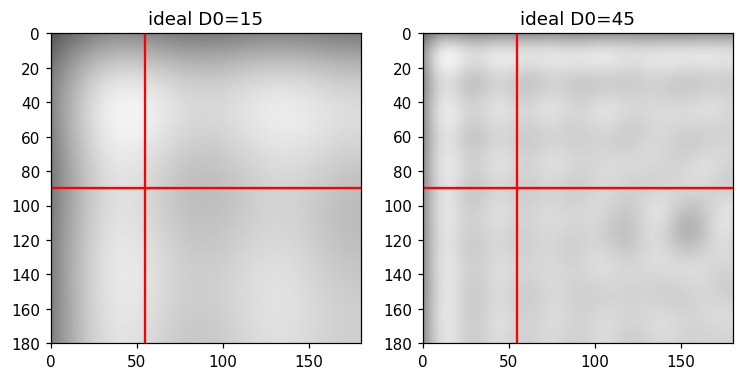

In [17]:

if "characters" in globals():
    z15=apply_filter(characters,"ideal",15); z45=apply_filter(characters,"ideal",45)
    fig,ax=plt.subplots(1,2,figsize=(8,4))
    for a,z,t in zip(ax,[z15,z45],["ideal D0=15","ideal D0=45"]):
        a.imshow(z,cmap="gray"); a.set_title(t); a.set_xlim(0,180); a.set_ylim(180,0)
        a.axvline(55,color="r"); a.axhline(90,color="r")
    savefig("10b_ringing_zoom_marked.png"); plt.show()
